# Final Camera-Ready Notebook

**Paper 786, ICRM 2026** — *MedFusionNet: Integrating Structured, Temporal, Waveform, and Text Data for Emergency Outcome Prediction*


| Modality | Source file | Representation |
|---|---|---|
| **S** Structured triage | `visits.csv` | age, sex, arrival mode, six triage vital signs |
| **T** Temporal vitals | `numerics.csv` | first 60 min of monitoring, 1-min grid, 7 vitals (GRU / GRU-D sequences and summary statistics) |
| **W** Waveform summary | `waveform_summary.csv` | per-encounter monitoring metadata (segments, duration, lead availability) |
| **X** Text | `visits.csv` → `CC` | Bio_ClinicalBERT `[CLS]` embedding of the chief complaint |

**Tasks:** (1) ICU admission (binary), (2) ED length of stay in hours (regression).

**What the reviewers asked for, and where it is produced**

| Reviewer request | Section |
|---|---|
| Confidence intervals / multiple runs | §7–§8: bootstrap 95% CIs, paired bootstrap differences, multi-seed mean ± SD |
| Baselines and ablations | §7–§8: unimodal, pairwise and full models, clinical baselines |
| Was GRU-D actually used? Exact fusion? | §6: model definitions; §8: GRU vs GRU-D vs fused model |
| XGBoost hyper-parameters, exact text checkpoint | §1 config, saved to `run_metadata.json` |
| List the waveform features | §3 |
| Which outcomes were evaluated | ICU admission and ED LOS only |
| Chronological split | §7–§8 are repeated on `split_chrono_*` |



## 1. Setup and configuration

In [1]:
import os, json, random, time, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve,
                             roc_curve, r2_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBClassifier, XGBRegressor

import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer

warnings.filterwarnings("ignore")

FAST = os.environ.get("MFN_FAST") == "1"     # smoke-test switch; must stay False for the paper run

SEED        = 42                              # primary seed (the run whose predictions get bootstrap CIs)
XGB_SEEDS   = [42, 43, 44, 45, 46] if not FAST else [42, 43]
NN_SEEDS    = [42, 43, 44] if not FAST else [42]
N_BOOT      = 2000 if not FAST else 100       # bootstrap resamples of the test set
T_WINDOW    = 60                              # minutes of monitoring used by the temporal branch
VITALS      = ["HR", "RR", "SpO2", "SBP", "DBP", "MAP", "Temp"]

TEXT_MODEL  = os.environ.get("MFN_TEXT_MODEL", "emilyalsentzer/Bio_ClinicalBERT")
MAX_LEN, BERT_BATCH = 64, 128

XGB_PARAMS  = dict(n_estimators=400 if not FAST else 60, max_depth=5, learning_rate=0.05,
                   subsample=0.8, colsample_bytree=0.8, tree_method="hist")
NN_PARAMS   = dict(hidden=64, lr=1e-3, weight_decay=1e-5, batch=512, grad_clip=5.0,
                   epochs=40 if not FAST else 3, patience=5)

SPLIT_KINDS = ["random", "chrono"]            # "chrono" is skipped automatically if its files are absent
RUN_JOINT_CLASSIFIER = True                   # also train the neural fusion model for ICU admission


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def find_data_dir():
    candidates = [os.environ.get("MFN_DATA"),
                  "/kaggle/input/datasets/abinayavinoth/health-care-mimic",
                  "/kaggle/input/health-care-mimic"]
    for c in candidates:
        if c and (Path(c) / "visits.csv").exists():
            return Path(c)
    root = Path("/kaggle/input")
    hits = sorted(root.rglob("visits.csv")) if root.exists() else []
    if hits:
        return hits[0].parent
    raise FileNotFoundError("visits.csv not found - attach the MC-MED dataset or set MFN_DATA.")


set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA = find_data_dir()
OUT = Path(os.environ.get("MFN_OUT", "/kaggle/working/medfusionnet_final"))
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
RUN_START = time.time()
print(f"Device: {DEVICE} | data: {DATA} | output: {OUT} | FAST={FAST}")
if DEVICE.type != "cuda":
    print("WARNING: no GPU detected - the GRU-D models will be very slow. Enable a GPU accelerator.")

Device: cuda | data: /kaggle/input/datasets/abinayavinoth/health-care-mimic | output: /kaggle/working/medfusionnet_final | FAST=False


## 2. Load encounters, splits and labels

The split files have **no header row**, so they are read with `header=None`. Encounters are keyed by `CSN`.

* **ICU admission** = `Admit_service` contains "Critical Care" or "ICU".
* **ED length of stay** = `ED_LOS` (hours).

In [2]:
def norm_csn(s):
    return s.astype(str).str.strip().str.replace(r"\.0$", "", regex=True)


visits = pd.read_csv(DATA / "visits.csv", low_memory=False)
visits.columns = visits.columns.str.strip()
visits["CSN"] = norm_csn(visits["CSN"])
visits = visits.drop_duplicates("CSN").reset_index(drop=True)
CSN_INDEX = pd.Index(visits["CSN"])
N = len(visits)

ICU = visits["Admit_service"].astype(str).str.contains("Critical Care|ICU", case=False, na=False).to_numpy().astype(int)
LOS = pd.to_numeric(visits["ED_LOS"], errors="coerce").to_numpy(dtype=np.float64)


def read_split(kind, part):
    path = DATA / f"split_{kind}_{part}.csv"
    if not path.exists():
        return None
    ids = norm_csn(pd.read_csv(path, header=None, dtype=str).iloc[:, 0])
    ids = ids[~ids.str.lower().isin(["csn", "nan", "none", ""])].drop_duplicates()
    pos = CSN_INDEX.get_indexer(ids)
    return pos[pos >= 0]


SPLITS = {}
for kind in SPLIT_KINDS:
    parts = {p: read_split(kind, p) for p in ("train", "val", "test")}
    if any(v is None for v in parts.values()):
        print(f"[{kind}] split files not found - skipped.")
        continue
    sets = {p: set(v.tolist()) for p, v in parts.items()}
    assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"]), \
        f"{kind}: encounter overlap between splits"
    SPLITS[kind] = parts
assert "random" in SPLITS, "split_random_* files are required"

rows = []
for kind, parts in SPLITS.items():
    mrn_train = set(visits["MRN"].to_numpy()[parts["train"]]) if "MRN" in visits else set()
    for p, idx in parts.items():
        los = LOS[idx][np.isfinite(LOS[idx])]
        shared = int(np.isin(visits["MRN"].to_numpy()[idx], list(mrn_train)).sum()) if (mrn_train and p != "train") else 0
        rows.append({"Split": kind, "Part": p, "Encounters": len(idx), "ICU admissions": int(ICU[idx].sum()),
                     "ICU prevalence (%)": round(100 * ICU[idx].mean(), 2),
                     "ED LOS median [IQR] (h)": f"{np.median(los):.2f} [{np.percentile(los, 25):.2f}-{np.percentile(los, 75):.2f}]",
                     "Encounters whose patient (MRN) is also in train": shared})
cohort_table = pd.DataFrame(rows)
cohort_table.to_csv(OUT / "table_cohort.csv", index=False)
print(f"Encounters: {N:,} | ICU admissions: {ICU.sum():,} ({100 * ICU.mean():.2f}%)")
display(cohort_table)

Encounters: 118,385 | ICU admissions: 1,684 (1.42%)


,Split,Part,Encounters,ICU admissions,ICU prevalence (%),ED LOS median [IQR] (h),Encounters whose patient (MRN) is also in train
0,random,train,94657,1355,1.43,5.37 [3.72-7.42],0
1,random,val,12062,175,1.45,5.35 [3.72-7.40],0
2,random,test,11666,154,1.32,5.28 [3.63-7.35],0
3,chrono,train,81588,1161,1.42,5.25 [3.62-7.30],0
4,chrono,val,11770,188,1.60,5.27 [3.63-7.30],0
5,chrono,test,12020,184,1.53,5.60 [3.97-7.68],0


## 3. Structured triage (S) and waveform-summary (W) features

**S (9 variables):** age, sex, means of arrival, triage temperature, heart rate, respiratory rate, SpO2, systolic and diastolic blood pressure.

**W (6 variables)** from `waveform_summary.csv`: total number of recorded segments, total recorded duration (s), number of waveform types, and availability flags for ECG lead II, plethysmography and respiration.
These are *monitoring metadata*. No raw waveform is processed, so there is no segment length or artifact-rejection step to report.

> **Timing caveat.** Segments and duration are totals over the whole ED encounter, so they are not known at triage and duration scales with length of stay.
> * ICU task: results are reported with all six W features **and** with the three availability flags only (`W-flags`) as a sensitivity analysis.
> * LOS task: only the availability flags are used; duration and segment counts are excluded as target leakage.

In [3]:
STRUCT_NUM = ["Age", "Triage_Temp", "Triage_HR", "Triage_RR", "Triage_SpO2", "Triage_SBP", "Triage_DBP"]
STRUCT_CAT = ["Gender", "Means_of_arrival"]

F = pd.DataFrame(index=visits.index)
for c in STRUCT_NUM:
    F[c] = pd.to_numeric(visits[c], errors="coerce")
for c in STRUCT_CAT:
    col = visits[c].astype(object)
    F[c] = col.where(col.notna(), np.nan)

wf = pd.read_csv(DATA / "waveform_summary.csv")
wf.columns = wf.columns.str.strip()
wf["CSN"] = norm_csn(wf["CSN"])
wf["Type"] = wf["Type"].astype(str).str.strip()
wf_agg = wf.groupby("CSN").agg(wf_total_segments=("Segments", "sum"), wf_total_duration=("Duration", "sum"),
                               wf_n_types=("Type", "nunique"))
wf_flag = pd.crosstab(wf["CSN"], wf["Type"]).gt(0).astype(int)
wf_flag = wf_flag[[c for c in ["II", "Pleth", "Resp"] if c in wf_flag.columns]].add_prefix("wf_has_")
wf_feat = wf_agg.join(wf_flag).reindex(CSN_INDEX).fillna(0.0)
wf_feat.index = F.index
F = pd.concat([F, wf_feat], axis=1)

S_COLS = STRUCT_NUM + STRUCT_CAT
W_FLAGS = list(wf_flag.columns)
W_COLS = ["wf_total_segments", "wf_total_duration", "wf_n_types"] + W_FLAGS
print("S features:", S_COLS)
print("W features:", W_COLS)
print(f"Encounters with any waveform record: {(wf_feat['wf_n_types'] > 0).mean() * 100:.1f}%")

S features: ['Age', 'Triage_Temp', 'Triage_HR', 'Triage_RR', 'Triage_SpO2', 'Triage_SBP', 'Triage_DBP', 'Gender', 'Means_of_arrival']
W features: ['wf_total_segments', 'wf_total_duration', 'wf_n_types', 'wf_has_II', 'wf_has_Pleth', 'wf_has_Resp']
Encounters with any waveform record: 70.6%


## 4. Temporal vital signs (T) from `numerics.csv`

`numerics.csv` is long format (`CSN, Source, Measure, Value, Time`). For each encounter the first 60 minutes after its first recorded vital sign are placed on a 1-minute grid for 7 vitals. Missing cells stay missing; a mask and a time-since-last-observation tensor are built for GRU-D.

**Timestamp fix.** MC-MED dates are shifted into the years 2200–2300, and pandas' nanosecond timestamps end in April 2262. With `pd.to_datetime(..., errors="coerce")` every later timestamp becomes `NaT` and its rows are dropped; the previous run reported 4,468,877 of 11,536,056 temporal rows (38.7%) as invalid timestamps, which matches this limit. Timestamps are parsed at second resolution here; the cell prints how many could not be parsed (expected: 0) and how many encounters have temporal data.

In [4]:
def _civil_seconds(s):
    """Arithmetic fallback: 'YYYY-MM-DDTHH:MM:SS' strings -> epoch seconds (NaN if malformed)."""
    num = lambda a, b: pd.to_numeric(s.str.slice(a, b), errors="coerce").to_numpy(dtype=np.float64)
    y, m, d, hh, mm, ss = num(0, 4), num(5, 7), num(8, 10), num(11, 13), num(14, 16), num(17, 19)
    y = y - (m <= 2)
    era = np.floor(y / 400)
    yoe = y - era * 400
    doy = np.floor((153 * (m + np.where(m > 2, -3, 9)) + 2) / 5) + d - 1
    doe = yoe * 365 + np.floor(yoe / 4) - np.floor(yoe / 100) + doy
    return (era * 146097 + doe - 719468) * 86400 + hh * 3600 + mm * 60 + ss


def parse_time_seconds(s):
    """ISO-8601 strings -> float64 epoch seconds without the datetime64[ns] year-2262 limit."""
    s = s.astype(str).str.slice(0, 19)
    s = s.where(s.str.len() == 19, "")                  # missing / malformed -> NaT
    try:
        arr = np.asarray(s.to_numpy(), dtype="U19").astype("datetime64[s]")
        out = arr.astype("int64").astype(np.float64)
        out[np.isnat(arr)] = np.nan
        return out
    except Exception:
        return _civil_seconds(s)


vital_code = {v: i for i, v in enumerate(VITALS)}
wanted = {"CSN", "Measure", "Value", "Time"}
chunks, n_rows, n_vital_rows, n_bad = [], 0, 0, 0
for chunk in pd.read_csv(DATA / "numerics.csv", usecols=lambda c: c.strip() in wanted,
                         chunksize=4_000_000, low_memory=False):
    chunk.columns = chunk.columns.str.strip()
    n_rows += len(chunk)
    code = chunk["Measure"].astype(str).str.strip().map(vital_code).to_numpy(dtype=np.float64)
    keep = np.isfinite(code)
    if not keep.any():
        continue
    chunk, code = chunk.loc[keep], code[keep]
    n_vital_rows += len(chunk)
    enc = CSN_INDEX.get_indexer(norm_csn(chunk["CSN"]))
    val = pd.to_numeric(chunk["Value"], errors="coerce").to_numpy(dtype=np.float32)
    sec = parse_time_seconds(chunk["Time"])
    ok = (enc >= 0) & np.isfinite(val) & np.isfinite(sec)
    n_bad += int((~np.isfinite(sec)).sum())
    chunks.append(pd.DataFrame({"enc": enc[ok].astype(np.int32), "v": code[ok].astype(np.int8),
                                "val": val[ok], "sec": sec[ok].astype(np.int64)}))
num = pd.concat(chunks, ignore_index=True)
del chunks
print(f"numerics rows: {n_rows:,} | rows for the 7 vitals: {n_vital_rows:,} | unparseable timestamps: {n_bad:,}")
assert n_bad <= 0.01 * max(n_vital_rows, 1), "More than 1% of timestamps could not be parsed - inspect numerics['Time']."

num["minute"] = ((num["sec"] - num.groupby("enc")["sec"].transform("min")) // 60).astype(np.int32)
num = num[num["minute"] < T_WINDOW]
cell = num.groupby(["enc", "minute", "v"], sort=False)["val"].mean().reset_index()
del num

SEQ = np.full((N, T_WINDOW, len(VITALS)), np.nan, dtype=np.float32)      # NaN = not observed
SEQ[cell["enc"].to_numpy(), cell["minute"].to_numpy(), cell["v"].to_numpy()] = cell["val"].to_numpy(dtype=np.float32)
del cell

OBS = np.isfinite(SEQ)
tgrid = np.arange(T_WINDOW, dtype=np.int16)[None, :, None]
last_obs = np.maximum.accumulate(np.where(OBS, tgrid, np.int16(-1)), axis=1)
DELTA = (tgrid - last_obs).astype(np.uint8)       # minutes since last observation (t+1 before the first one)
HAS_SEQ = OBS.any(axis=(1, 2))

# Summary statistics of the same 60-minute window (temporal modality for tree models; NaN = never measured)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ts = {"mean": np.nanmean(SEQ, axis=1), "min": np.nanmin(SEQ, axis=1),
          "max": np.nanmax(SEQ, axis=1), "std": np.nanstd(SEQ, axis=1)}
li = last_obs[:, -1, :].astype(np.int64)
ts["last"] = np.take_along_axis(SEQ, np.clip(li, 0, None)[:, None, :], axis=1)[:, 0, :]
ts["last"][li < 0] = np.nan
ts["n"] = OBS.sum(axis=1).astype(np.float32)
ts_frame = pd.DataFrame({f"ts_{v}_{k}": a[:, j] for k, a in ts.items() for j, v in enumerate(VITALS)}, index=F.index)
F = pd.concat([F, ts_frame], axis=1)
T_COLS = list(ts_frame.columns)
del ts, ts_frame, last_obs, li

missing_table = pd.DataFrame({"Vital": VITALS,
                              "Observed cells (%)": (100 * OBS[HAS_SEQ].mean(axis=(0, 1))).round(2),
                              "Encounters with >=1 value (%)": (100 * OBS[HAS_SEQ].any(axis=1).mean(axis=0)).round(2)})
missing_table["Missing cells (%)"] = (100 - missing_table["Observed cells (%)"]).round(2)
missing_table.to_csv(OUT / "table_temporal_missingness.csv", index=False)
print(f"Encounters with temporal data: {HAS_SEQ.sum():,} / {N:,} ({100 * HAS_SEQ.mean():.1f}%) | "
      f"overall missing cells: {100 * (1 - OBS[HAS_SEQ].mean()):.1f}%")
display(missing_table)

numerics rows: 47,821,508 | rows for the 7 vitals: 28,743,244 | unparseable timestamps: 0
Encounters with temporal data: 101,876 / 118,385 (86.1%) | overall missing cells: 85.2%


,Vital,Observed cells (%),Encounters with >=1 value (%),Missing cells (%)
0,HR,27.85,99.58,72.15
1,RR,24.75,99.31,75.25
2,SpO2,34.00,99.71,66.00
3,SBP,5.24,99.47,94.76
4,DBP,5.18,99.46,94.82
5,MAP,5.18,99.46,94.82
6,Temp,1.68,96.79,98.32


## 5. Text (X): Bio_ClinicalBERT chief-complaint embeddings

Checkpoint `emilyalsentzer/Bio_ClinicalBERT` (frozen), max 64 tokens, `[CLS]` vector of the last layer (768-d). Only the triage chief complaint (`CC`) is encoded; radiology text is not used. Identical complaint strings are encoded once and cached.

In [5]:
TEXT_COL = next((c for c in ["CC", "Chief_complaint", "Chief_Complaint", "chief_complaint"] if c in visits.columns), None)
assert TEXT_COL is not None, "No chief-complaint column found in visits.csv"
texts = visits[TEXT_COL].fillna("").astype(str).str.strip()
codes, uniq = pd.factorize(texts)
uniq = [str(u) for u in uniq]
print(f"Text column: {TEXT_COL} | non-empty: {100 * (texts != '').mean():.2f}% | unique strings: {len(uniq):,}")

emb_path, meta_path = OUT / "text_emb_unique.npy", OUT / "text_emb_unique.json"
meta = {"model": TEXT_MODEL, "max_len": MAX_LEN, "texts": uniq}
if emb_path.exists() and meta_path.exists() and json.load(open(meta_path)) == meta:
    emb_unique = np.load(emb_path)
    print("Loaded cached embeddings.")
else:
    tok = AutoTokenizer.from_pretrained(TEXT_MODEL)
    bert = AutoModel.from_pretrained(TEXT_MODEL).to(DEVICE).eval()
    emb_unique = np.zeros((len(uniq), bert.config.hidden_size), dtype=np.float32)
    order = np.argsort([len(u) for u in uniq])
    with torch.no_grad():
        for i in range(0, len(uniq), BERT_BATCH):
            ids = order[i:i + BERT_BATCH]
            batch = tok([uniq[j] for j in ids], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            emb_unique[ids] = bert(**batch).last_hidden_state[:, 0, :].float().cpu().numpy()
    np.save(emb_path, emb_unique)
    json.dump(meta, open(meta_path, "w"))
    del bert, tok
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
E = emb_unique[codes]
print("Embedding matrix:", E.shape)

Text column: CC | non-empty: 99.95% | unique strings: 10,750


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding matrix: (118385, 768)


## 6. Models and evaluation helpers

**Tree models.** XGBoost on the concatenated tabular modalities (S, W, T-summaries); median imputation for S fitted on the training split, native missing-value handling for T-summaries.

**Text model.** Logistic regression on the frozen embedding.

**Late fusion (MedFusionNet-LF).** $p = (1-w)\,p_{\text{tab}} + w\,p_{\text{text}}$ with $w$ chosen on the validation split.

**Joint fusion network (MedFusionNet-Joint).** GRU-D over the 60-minute sequence, an MLP over S (+W) and a projection of the text embedding; the three vectors are concatenated and trained end-to-end:
$h = [\,h_{\text{GRU-D}}(x_{1:60}, m_{1:60}, \delta_{1:60}) \;\|\; f_S(x_S, x_W) \;\|\; f_X(e_{\text{text}})\,]$, $\hat y = g(h)$.

**Uncertainty.** Percentile bootstrap of the test set (same resamples for every model, so differences are paired) and repeated training with different seeds.

In [6]:
# ---------- metrics ----------
def fast_auc(y, p):
    r = rankdata(p)
    n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))


def boot_p(d):
    return float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean())))


def bootstrap_classification(y, preds, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    auc = {k: np.empty(n_boot) for k in preds}; ap = {k: np.empty(n_boot) for k in preds}
    b = 0
    while b < n_boot:
        i = rng.integers(0, len(y), len(y))
        yb = y[i]
        if yb.min() == yb.max():
            continue
        for k, p in preds.items():
            auc[k][b] = fast_auc(yb, p[i]); ap[k][b] = average_precision_score(yb, p[i])
        b += 1
    return auc, ap


def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[int(np.argmax(f1))])


def threshold_metrics(y, p, thr):
    pred = p >= thr
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); ppv = tp / max(tp + fp, 1); npv = tn / max(tn + fn, 1)
    return {"Sensitivity": sens, "Specificity": spec, "PPV": ppv, "NPV": npv,
            "F1": 2 * ppv * sens / max(ppv + sens, 1e-12), "Accuracy": (tp + tn) / len(y)}


def reg_metrics(y, p):
    e = p - y
    return {"MAE": float(np.abs(e).mean()), "RMSE": float(np.sqrt((e ** 2).mean())),
            "MedAE": float(np.median(np.abs(e))), "R2": float(r2_score(y, p))}


def bootstrap_regression(y, preds, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    mae = {k: np.empty(n_boot) for k in preds}; rmse = {k: np.empty(n_boot) for k in preds}
    for b in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        for k, p in preds.items():
            e = p[i] - y[i]
            mae[k][b] = np.abs(e).mean(); rmse[k][b] = np.sqrt((e ** 2).mean())
    return mae, rmse


# ---------- tabular preprocessing (fitted on the training split only) ----------
def make_tab(cols, frames):
    """Median-imputed S/W numerics, raw T-summaries (NaN kept for XGBoost), one-hot categoricals."""
    cats = [c for c in cols if c in STRUCT_CAT]
    tsc = [c for c in cols if c.startswith("ts_")]
    nums = [c for c in cols if c not in cats and c not in tsc]
    steps = [("num", SimpleImputer(strategy="median"), nums)]
    if tsc:
        steps.append(("ts", "passthrough", tsc))
    if cats:
        steps.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats))
    ct = ColumnTransformer(steps, remainder="drop")
    mats = [np.asarray(ct.fit_transform(frames[0][cols]), dtype=np.float32)]
    mats += [np.asarray(ct.transform(f[cols]), dtype=np.float32) for f in frames[1:]]
    names = nums + tsc
    if cats:
        names += list(ct.named_transformers_["cat"].named_steps["oh"].get_feature_names_out(cats))
    return mats, names


def make_dense(cols, frames):
    """Imputed + standardised dense matrix for linear / neural models (log1p on waveform counts)."""
    cats = [c for c in cols if c in STRUCT_CAT]
    nums = [c for c in cols if c not in cats]
    frames = [f[cols].copy() for f in frames]
    for f in frames:
        for c in ("wf_total_segments", "wf_total_duration"):
            if c in f:
                f[c] = np.log1p(f[c])
    steps = [("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                               ("sc", StandardScaler())]), nums)]
    if cats:
        steps.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats))
    ct = ColumnTransformer(steps, remainder="drop")
    return [np.asarray(ct.fit_transform(frames[0]), dtype=np.float32)] + \
           [np.asarray(ct.transform(f), dtype=np.float32) for f in frames[1:]]


# ---------- temporal tensors ----------
def seq_stats(rows):
    x = SEQ[rows]
    mu = np.nan_to_num(np.nanmean(x, axis=(0, 1)))
    sd = np.nanstd(x, axis=(0, 1))
    sd = np.where(np.isfinite(sd) & (sd > 1e-6), sd, 1.0)
    return mu.astype(np.float32), sd.astype(np.float32)


def seq_arrays(rows, mu, sd):
    x = SEQ[rows]
    m = np.isfinite(x)
    z = np.where(m, (x - mu) / sd, 0.0).astype(np.float32)       # 0 = training mean after standardisation
    return z, m.astype(np.float32), DELTA[rows].astype(np.float32) / T_WINDOW


# ---------- neural models ----------
class GRUD(nn.Module):
    """GRU-D (Che et al., 2018): learned decay of the last observation and of the hidden state."""

    def __init__(self, d, h):
        super().__init__()
        self.h = h
        self.gamma_x = nn.Linear(d, d)
        self.gamma_h = nn.Linear(d, h)
        self.cell = nn.GRUCell(2 * d, h)

    def forward(self, X, M, D):
        B, T, d = X.shape
        h = X.new_zeros(B, self.h)
        x_last = X.new_zeros(B, d)
        gx = torch.exp(-torch.relu(self.gamma_x(D)))
        gh = torch.exp(-torch.relu(self.gamma_h(D)))
        for t in range(T):
            m, x = M[:, t], X[:, t]
            x_last = m * x + (1 - m) * x_last
            x_hat = m * x + (1 - m) * gx[:, t] * x_last          # decays towards the training mean (0)
            h = self.cell(torch.cat([x_hat, m], dim=1), gh[:, t] * h)
        return h


class MedFusionNet(nn.Module):
    """Temporal encoder (GRU-D or GRU) || static MLP || text projection -> prediction head."""

    def __init__(self, d_seq, d_static=0, d_text=0, temporal="grud", hidden=64, out_bias=0.0):
        super().__init__()
        self.kind = temporal
        dims = 0
        if temporal == "grud":
            self.temporal = GRUD(d_seq, hidden); dims += hidden
        elif temporal == "gru":
            self.temporal = nn.GRU(d_seq, hidden, batch_first=True); dims += hidden
        self.static = nn.Sequential(nn.Linear(d_static, 64), nn.ReLU(), nn.Dropout(0.1),
                                    nn.Linear(64, 32), nn.ReLU()) if d_static else None
        self.text = nn.Sequential(nn.LayerNorm(d_text), nn.Linear(d_text, 64), nn.ReLU(), nn.Dropout(0.2),
                                  nn.Linear(64, 32), nn.ReLU()) if d_text else None
        dims += 32 * (d_static > 0) + 32 * (d_text > 0)
        if d_static or d_text:
            self.head = nn.Sequential(nn.Linear(dims, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 1))
            nn.init.constant_(self.head[-1].bias, out_bias)
        else:
            self.head = nn.Linear(dims, 1)
            nn.init.constant_(self.head.bias, out_bias)

    def forward(self, b):
        parts = []
        if self.kind == "grud":
            parts.append(self.temporal(b["X"], b["M"], b["D"]))
        elif self.kind == "gru":
            parts.append(self.temporal(b["X"])[1][-1])
        if self.static is not None:
            parts.append(self.static(b["S"]))
        if self.text is not None:
            parts.append(self.text(b["E"]))
        return self.head(torch.cat(parts, dim=1)).squeeze(-1)


def to_dev(a):
    return torch.as_tensor(np.ascontiguousarray(a), dtype=torch.float32, device=DEVICE)


@torch.no_grad()
def predict_nn(model, data, task):
    model.eval()
    n = len(data["y"]); out = []
    for i in range(0, n, 2048):
        o = model({k: v[i:i + 2048] for k, v in data.items() if k != "y"})
        out.append(torch.sigmoid(o) if task == "clf" else o)
    p = torch.cat(out).float().cpu().numpy()
    if not np.isfinite(p).all():
        raise FloatingPointError("Non-finite predictions.")
    return p


def train_nn(make_model, tr, va, task, seed, tag=""):
    """Adam + early stopping on the validation split (RMSE for regression, AUROC for classification)."""
    set_seed(seed)
    model = make_model().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=NN_PARAMS["lr"], weight_decay=NN_PARAMS["weight_decay"])
    loss_fn = nn.MSELoss() if task == "reg" else nn.BCEWithLogitsLoss()
    yv = va["y"].cpu().numpy()
    n, bs = len(tr["y"]), NN_PARAMS["batch"]
    best, best_state, best_ep, bad, t0 = np.inf, None, 0, 0, time.time()
    for ep in range(1, NN_PARAMS["epochs"] + 1):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            loss = loss_fn(model({k: v[idx] for k, v in tr.items() if k != "y"}), tr["y"][idx])
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite training loss.")
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), NN_PARAMS["grad_clip"])
            opt.step()
        pv = predict_nn(model, va, task)
        score = float(np.sqrt(((pv - yv) ** 2).mean())) if task == "reg" else -fast_auc(yv.astype(int), pv)
        if score < best - 1e-4:
            best, bad, best_ep = score, 0, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= NN_PARAMS["patience"]:
                break
    model.load_state_dict(best_state)
    metric = f"val RMSE {best:.4f}" if task == "reg" else f"val AUROC {-best:.4f}"
    print(f"   {tag:<34s} seed {seed}: best epoch {best_ep:>2d}/{ep}, {metric} ({time.time() - t0:.0f}s)")
    return model


def n_params(make_model):
    return sum(p.numel() for p in make_model().parameters())


print("Helpers ready.")

Helpers ready.


## 7. ICU admission

Every model is trained on the training split; the fusion weight and decision threshold are chosen on the validation split; the test split is used once. Because ICU admission is rare (about 1.4%), **AUROC and AUPRC are the primary metrics**; accuracy is uninformative at this prevalence. Threshold metrics use the validation F1-optimal threshold.

In [7]:
W_GRID = np.round(np.linspace(0, 1, 21), 2)

CLS_LABELS = {   # key -> (model description, modalities)
    "esi":            ("Triage acuity only (logistic regression)", "clinical baseline"),
    "lr_S":           ("Logistic regression", "S"),
    "S":              ("XGBoost", "S"),
    "S+T":            ("XGBoost", "S+T"),
    "S+Wf":           ("XGBoost", "S+W-flags"),
    "S+W":            ("XGBoost", "S+W"),
    "S+T+Wf":         ("XGBoost", "S+T+W-flags"),
    "S+T+W":          ("XGBoost", "S+T+W"),
    "X":              ("Bio_ClinicalBERT + logistic regression", "X"),
    "S|X":            ("Late fusion", "S+X"),
    "S+W|X":          ("Late fusion", "S+W+X"),
    "S+T+Wf|X":       ("Late fusion (sensitivity: W-flags)", "S+T+W-flags+X"),
    "S+T+W|X":        ("MedFusionNet-LF (late fusion)", "S+T+W+X"),
    "early":          ("Feature-level fusion (XGBoost, 32-d PCA text)", "S+T+W+X"),
    "joint":          ("MedFusionNet-Joint (GRU-D + MLP + text)", "S+T+W+X"),
}
TAB_SETS = {"S": S_COLS, "S+T": S_COLS + T_COLS, "S+Wf": S_COLS + W_FLAGS, "S+W": S_COLS + W_COLS,
            "S+T+Wf": S_COLS + T_COLS + W_FLAGS, "S+T+W": S_COLS + T_COLS + W_COLS}
FUSIONS = {"S|X": "S", "S+W|X": "S+W", "S+T+Wf|X": "S+T+Wf", "S+T+W|X": "S+T+W"}
CLS_COMPARISONS = [("S+T+W|X", "S"), ("S+T+W|X", "X"), ("S+T+W|X", "S+T+W"), ("S+W|X", "S+W"),
                   ("S+W", "S"), ("S+T", "S"), ("S+T+W", "S+T+Wf"), ("joint", "S+T+W|X"), ("S", "esi")]


def run_classification(kind):
    sp = SPLITS[kind]
    parts = ("train", "val", "test")
    y = {p: ICU[sp[p]] for p in parts}
    frames = [F.iloc[sp[p]] for p in parts]
    PV, PT, seed_rows, extra = {}, {}, [], {"weights": {}, "weight_curve": {}}
    print(f"\n===== ICU admission | {kind} split | train {len(y['train']):,} (ICU {y['train'].sum():,}) | "
          f"val {len(y['val']):,} | test {len(y['test']):,} (ICU {y['test'].sum():,}) =====")

    # --- text branch ---
    txt = LogisticRegression(max_iter=1000, random_state=SEED).fit(E[sp["train"]], y["train"])
    PV["X"], PT["X"] = txt.predict_proba(E[sp["val"]])[:, 1], txt.predict_proba(E[sp["test"]])[:, 1]

    # --- XGBoost on tabular modality sets, repeated over seeds ---
    for name, cols in TAB_SETS.items():
        mats, feat_names = make_tab(cols, frames)
        for s in XGB_SEEDS:
            m = XGBClassifier(**XGB_PARAMS, eval_metric="logloss", random_state=s).fit(mats[0], y["train"])
            pv, pt = m.predict_proba(mats[1])[:, 1], m.predict_proba(mats[2])[:, 1]
            seed_rows.append({"key": name, "seed": s, "AUROC": fast_auc(y["test"], pt),
                              "AUPRC": average_precision_score(y["test"], pt)})
            fkey = next((k for k, v in FUSIONS.items() if v == name), None)
            if fkey:
                curve = [fast_auc(y["val"], (1 - w) * pv + w * PV["X"]) for w in W_GRID]
                w = float(W_GRID[int(np.argmax(curve))])
                pf = (1 - w) * pt + w * PT["X"]
                seed_rows.append({"key": fkey, "seed": s, "AUROC": fast_auc(y["test"], pf),
                                  "AUPRC": average_precision_score(y["test"], pf)})
            if s == SEED:
                PV[name], PT[name] = pv, pt
                if fkey:
                    PV[fkey], PT[fkey] = (1 - w) * pv + w * PV["X"], pf
                    extra["weights"][fkey] = w; extra["weight_curve"][fkey] = curve
                if name == "S+T+W":
                    extra["shap"] = (m, mats[2], feat_names)
                    full_mats = mats
        print(f"   XGBoost {name:<8s} done ({len(XGB_SEEDS)} seeds)")

    # --- feature-level fusion: tabular features || 32-d PCA of the text embedding ---
    pca = PCA(n_components=min(32, E.shape[1]), random_state=SEED).fit(E[sp["train"]])
    em = [np.hstack([full_mats[i], pca.transform(E[sp[p]]).astype(np.float32)]) for i, p in enumerate(parts)]
    m = XGBClassifier(**XGB_PARAMS, eval_metric="logloss", random_state=SEED).fit(em[0], y["train"])
    PV["early"], PT["early"] = m.predict_proba(em[1])[:, 1], m.predict_proba(em[2])[:, 1]
    del em

    # --- simple baselines ---
    d = make_dense(S_COLS, frames)
    m = LogisticRegression(max_iter=2000).fit(d[0], y["train"])
    PV["lr_S"], PT["lr_S"] = m.predict_proba(d[1])[:, 1], m.predict_proba(d[2])[:, 1]
    if "Triage_acuity" in visits.columns:
        acu = visits["Triage_acuity"].fillna("Unknown").astype(str).to_numpy().reshape(-1, 1)
        oh = OneHotEncoder(handle_unknown="ignore").fit(acu[sp["train"]])
        m = LogisticRegression(max_iter=2000).fit(oh.transform(acu[sp["train"]]), y["train"])
        PV["esi"], PT["esi"] = (m.predict_proba(oh.transform(acu[sp[p]]))[:, 1] for p in ("val", "test"))

    # --- joint neural fusion model ---
    if RUN_JOINT_CLASSIFIER:
        mu, sd = seq_stats(sp["train"])
        stat = make_dense(S_COLS + W_COLS, frames)
        data = {}
        for i, p in enumerate(parts):
            z, mk, dl = seq_arrays(sp[p], mu, sd)
            data[p] = {"X": to_dev(z), "M": to_dev(mk), "D": to_dev(dl), "S": to_dev(stat[i]),
                       "E": to_dev(E[sp[p]]), "y": to_dev(y[p])}
        prev = float(np.clip(y["train"].mean(), 1e-4, 0.5))
        mk_model = lambda: MedFusionNet(len(VITALS), stat[0].shape[1], E.shape[1], "grud", NN_PARAMS["hidden"],
                                        out_bias=float(np.log(prev / (1 - prev))))
        for s in NN_SEEDS:
            net = train_nn(mk_model, data["train"], data["val"], "clf", s, "MedFusionNet-Joint")
            pv, pt = predict_nn(net, data["val"], "clf"), predict_nn(net, data["test"], "clf")
            seed_rows.append({"key": "joint", "seed": s, "AUROC": fast_auc(y["test"], pt),
                              "AUPRC": average_precision_score(y["test"], pt)})
            if s == SEED:
                PV["joint"], PT["joint"] = pv, pt
        del data, net
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # --- test-set evaluation ---
    keys = [k for k in CLS_LABELS if k in PT]
    auc_b, ap_b = bootstrap_classification(y["test"], {k: PT[k] for k in keys})
    rows = []
    for k in keys:
        thr = best_f1_threshold(y["val"], PV[k])
        tm = threshold_metrics(y["test"], PT[k], thr)
        thr95 = float(np.quantile(PV[k][y["val"] == 0], 0.95))
        auc, ap = fast_auc(y["test"], PT[k]), average_precision_score(y["test"], PT[k])
        rows.append({"key": k, "Model": CLS_LABELS[k][0], "Modalities": CLS_LABELS[k][1],
                     "Val AUROC": round(fast_auc(y["val"], PV[k]), 4),
                     "AUROC": round(auc, 4), "AUROC 95% CI": "(%.3f-%.3f)" % ci(auc_b[k]),
                     "AUPRC": round(ap, 4), "AUPRC 95% CI": "(%.3f-%.3f)" % ci(ap_b[k]),
                     "Brier": round(brier_score_loss(y["test"], PT[k]), 4), "Threshold": round(thr, 3),
                     **{m_: round(v, 3) for m_, v in tm.items()},
                     "Sens@95%Spec": round(threshold_metrics(y["test"], PT[k], thr95)["Sensitivity"], 3)})
    table = pd.DataFrame(rows)

    delta = []
    for a, b in CLS_COMPARISONS:
        if a in PT and b in PT:
            da, dp = auc_b[a] - auc_b[b], ap_b[a] - ap_b[b]
            delta.append({"Comparison": f"[{CLS_LABELS[a][1]}] {CLS_LABELS[a][0]}  vs  [{CLS_LABELS[b][1]}] {CLS_LABELS[b][0]}",
                          "dAUROC": round(fast_auc(y["test"], PT[a]) - fast_auc(y["test"], PT[b]), 4),
                          "dAUROC 95% CI": "(%.4f to %.4f)" % ci(da), "p (AUROC)": round(boot_p(da), 4),
                          "dAUPRC": round(average_precision_score(y["test"], PT[a]) - average_precision_score(y["test"], PT[b]), 4),
                          "dAUPRC 95% CI": "(%.4f to %.4f)" % ci(dp), "p (AUPRC)": round(boot_p(dp), 4)})
    delta = pd.DataFrame(delta)

    sd_tab = pd.DataFrame(seed_rows).groupby("key").agg(seeds=("seed", "nunique"), AUROC_mean=("AUROC", "mean"),
                                                        AUROC_sd=("AUROC", "std"), AUPRC_mean=("AUPRC", "mean"),
                                                        AUPRC_sd=("AUPRC", "std")).round(4)
    sd_tab = sd_tab.reindex([k for k in CLS_LABELS if k in sd_tab.index]).reset_index()
    sd_tab.insert(1, "Model", [f"{CLS_LABELS[k][0]} [{CLS_LABELS[k][1]}]" for k in sd_tab["key"]])

    table.to_csv(OUT / f"table_icu_{kind}.csv", index=False)
    delta.to_csv(OUT / f"table_icu_differences_{kind}.csv", index=False)
    sd_tab.to_csv(OUT / f"table_icu_seeds_{kind}.csv", index=False)
    return {"y": y, "PV": PV, "PT": PT, "table": table, "delta": delta, "seeds": sd_tab, **extra}


CLS = {kind: run_classification(kind) for kind in SPLITS}


===== ICU admission | random split | train 94,657 (ICU 1,355) | val 12,062 | test 11,666 (ICU 154) =====
   XGBoost S        done (5 seeds)
   XGBoost S+T      done (5 seeds)
   XGBoost S+Wf     done (5 seeds)
   XGBoost S+W      done (5 seeds)
   XGBoost S+T+Wf   done (5 seeds)
   XGBoost S+T+W    done (5 seeds)
   MedFusionNet-Joint                 seed 42: best epoch  6/11, val AUROC 0.9196 (90s)

===== ICU admission | chrono split | train 81,588 (ICU 1,161) | val 11,770 | test 12,020 (ICU 184) =====
   XGBoost S        done (5 seeds)
   XGBoost S+T      done (5 seeds)
   XGBoost S+Wf     done (5 seeds)
   XGBoost S+W      done (5 seeds)
   XGBoost S+T+Wf   done (5 seeds)
   XGBoost S+T+W    done (5 seeds)
   MedFusionNet-Joint                 seed 42: best epoch  4/9, val AUROC 0.9285 (63s)
   MedFusionNet-Joint                 seed 43: best epoch  4/9, val AUROC 0.9266 (64s)
   MedFusionNet-Joint                 seed 44: best epoch 13/18, val AUROC 0.9259 (127s)


In [8]:
for kind, r in CLS.items():
    print(f"\n################ ICU admission - {kind} split - test set ################")
    display(r["table"].drop(columns="key"))
    print("Paired bootstrap differences (first model minus second):")
    display(r["delta"])
    print("Stability across training seeds (mean and SD of test metrics):")
    display(r["seeds"].drop(columns="key"))
    print("Validation-selected text weights:", r["weights"])


################ ICU admission - random split - test set ################


,Model,Modalities,Val AUROC,AUROC,AUROC 95% CI,AUPRC,AUPRC 95% CI,Brier,Threshold,Sensitivity,Specificity,PPV,NPV,F1,Accuracy,Sens@95%Spec
0,Triage acuity only (logistic regression),clinical baseline,0.8282,0.7990,(0.765-0.833),0.0918,(0.061-0.134),0.0121,0.373,0.201,0.994,0.313,0.989,0.245,0.984,0.773
1,Logistic regression,S,0.8350,0.8214,(0.780-0.859),0.1271,(0.085-0.179),0.0123,0.080,0.227,0.983,0.154,0.990,0.183,0.973,0.409
2,XGBoost,S,0.8649,0.8602,(0.827-0.889),0.1802,(0.128-0.246),0.0119,0.152,0.240,0.991,0.259,0.990,0.249,0.981,0.468
3,XGBoost,S+T,0.9066,0.8745,(0.845-0.903),0.2344,(0.168-0.313),0.0114,0.187,0.253,0.994,0.355,0.990,0.295,0.984,0.500
4,XGBoost,S+W-flags,0.8837,0.8656,(0.836-0.893),0.1843,(0.131-0.253),0.0118,0.212,0.175,0.994,0.290,0.989,0.219,0.983,0.468
5,XGBoost,S+W,0.8964,0.8795,(0.851-0.906),0.1745,(0.124-0.243),0.0120,0.123,0.266,0.985,0.197,0.990,0.227,0.976,0.506
6,XGBoost,S+T+W-flags,0.9096,0.8775,(0.849-0.905),0.2490,(0.179-0.329),0.0112,0.101,0.344,0.985,0.232,0.991,0.277,0.976,0.494
7,XGBoost,S+T+W,0.9188,0.8894,(0.863-0.915),0.2492,(0.182-0.328),0.0112,0.129,0.325,0.989,0.281,0.991,0.301,0.980,0.552
8,Bio_ClinicalBERT + logistic regression,X,0.8009,0.7718,(0.733-0.810),0.0766,(0.050-0.123),0.0126,0.087,0.078,0.995,0.171,0.988,0.107,0.983,0.260
9,Late fusion,S+X,0.8920,0.8737,(0.842-0.902),0.1944,(0.140-0.260),0.0118,0.099,0.325,0.988,0.260,0.991,0.289,0.979,0.519


Paired bootstrap differences (first model minus second):


,Comparison,dAUROC,dAUROC 95% CI,p (AUROC),dAUPRC,dAUPRC 95% CI,p (AUPRC)
0,[S+T+W+X] MedFusionNet-LF (late fusion) vs [...,0.0347,(0.0127 to 0.0582),0.001,0.0739,(0.0195 to 0.1326),0.005
1,[S+T+W+X] MedFusionNet-LF (late fusion) vs [...,0.1230,(0.0887 to 0.1582),0.000,0.1775,(0.1052 to 0.2573),0.000
2,[S+T+W+X] MedFusionNet-LF (late fusion) vs [...,0.0055,(-0.0013 to 0.0136),0.139,0.0049,(-0.0011 to 0.0114),0.094
3,[S+W+X] Late fusion vs [S+W] XGBoost,0.0051,(-0.0058 to 0.0174),0.361,0.0136,(0.0045 to 0.0237),0.000
4,[S+W] XGBoost vs [S] XGBoost,0.0194,(0.0036 to 0.0367),0.019,-0.0057,(-0.0340 to 0.0250),0.693
5,[S+T] XGBoost vs [S] XGBoost,0.0143,(-0.0116 to 0.0400),0.274,0.0542,(-0.0027 to 0.1139),0.066
6,[S+T+W] XGBoost vs [S+T+W-flags] XGBoost,0.0118,(0.0015 to 0.0216),0.028,0.0002,(-0.0298 to 0.0306),0.969
7,[S+T+W+X] MedFusionNet-Joint (GRU-D + MLP + te...,0.0089,(-0.0038 to 0.0213),0.182,-0.0383,(-0.0848 to 0.0084),0.101
8,[S] XGBoost vs [clinical baseline] Triage ac...,0.0611,(0.0222 to 0.0964),0.002,0.0884,(0.0340 to 0.1496),0.001


Stability across training seeds (mean and SD of test metrics):


...

Paired bootstrap differences (first model minus second):


,Comparison,dAUROC,dAUROC 95% CI,p (AUROC),dAUPRC,dAUPRC 95% CI,p (AUPRC)
0,[S+T+W+X] MedFusionNet-LF (late fusion) vs [...,0.0599,(0.0384 to 0.0838),0.000,0.1053,(0.0530 to 0.1563),0.000
1,[S+T+W+X] MedFusionNet-LF (late fusion) vs [...,0.1038,(0.0786 to 0.1298),0.000,0.1987,(0.1369 to 0.2691),0.000
2,[S+T+W+X] MedFusionNet-LF (late fusion) vs [...,0.0072,(-0.0026 to 0.0184),0.143,0.0035,(0.0008 to 0.0069),0.014
3,[S+W+X] Late fusion vs [S+W] XGBoost,0.0128,(-0.0013 to 0.0277),0.070,0.0150,(0.0060 to 0.0250),0.002
4,[S+W] XGBoost vs [S] XGBoost,0.0308,(0.0158 to 0.0470),0.000,0.0227,(-0.0021 to 0.0476),0.078
5,[S+T] XGBoost vs [S] XGBoost,0.0379,(0.0154 to 0.0614),0.001,0.0850,(0.0333 to 0.1372),0.001
6,[S+T+W] XGBoost vs [S+T+W-flags] XGBoost,0.0074,(0.0006 to 0.0149),0.037,0.0206,(-0.0039 to 0.0458),0.106
7,[S+T+W+X] MedFusionNet-Joint (GRU-D + MLP + te...,-0.0095,(-0.0199 to 0.0022),0.097,-0.0034,(-0.0483 to 0.0446),0.929
8,[S] XGBoost vs [clinical baseline] Triage ac...,0.0260,(-0.0055 to 0.0572),0.092,0.0299,(-0.0205 to 0.0905),0.240


Stability across training seeds (mean and SD of test metrics):


,Model,seeds,AUROC_mean,AUROC_sd,AUPRC_mean,AUPRC_sd
0,XGBoost [S],5,0.8473,0.0020,0.1674,0.0031
1,XGBoost [S+T],5,0.8882,0.0023,0.2542,0.0099
2,XGBoost [S+W-flags],5,0.8672,0.0017,0.1659,0.0060
3,XGBoost [S+W],5,0.8787,0.0013,0.1979,0.0067
4,XGBoost [S+T+W-flags],5,0.8957,0.0026,0.2549,0.0030
5,XGBoost [S+T+W],5,0.9022,0.0011,0.2772,0.0084
6,Late fusion [S+X],5,0.8737,0.0019,0.1824,0.0028
7,Late fusion [S+W+X],5,0.8924,0.0012,0.2115,0.0069
8,Late fusion (sensitivity: W-flags) [S+T+W-flag...,5,0.9040,0.0022,0.2587,0.0031
9,MedFusionNet-LF (late fusion) [S+T+W+X],5,0.9090,0.0012,0.2809,0.0069


Validation-selected text weights: {'S|X': 0.25, 'S+W|X': 0.3, 'S+T+Wf|X': 0.1, 'S+T+W|X': 0.1}


## 8. ED length of stay

Cohort: encounters with a valid `ED_LOS` and at least one vital sign in the 60-minute window. All models are scored on the same test encounters.

* **Reference baselines:** training-set mean and median. A regression model is only useful if it beats these.
* **Tree / linear models:** XGBoost on S, S+W-flags, S+T-summaries+W-flags; ridge regression on the text embedding.
* **Sequence models:** GRU (zero-imputed input) and GRU-D (mask + decay) on the 60-minute sequence.
* **MedFusionNet-Joint:** GRU-D with S, W-flags and text, added one modality at a time.

Loss: mean squared error on LOS in hours. W uses availability flags only (see §3). The target is total ED LOS from arrival; inputs are limited to the first 60 minutes of monitoring.

In [9]:
LOS_LABELS = {
    "mean":      ("Training mean", "reference"),
    "median":    ("Training median", "reference"),
    "xgb_S":     ("XGBoost", "S"),
    "xgb_SW":    ("XGBoost", "S+W-flags"),
    "ridge_X":   ("Ridge on Bio_ClinicalBERT embedding", "X"),
    "xgb_STW":   ("XGBoost", "S+T+W-flags"),
    "xgb_STWX":  ("XGBoost, feature-level (32-d PCA text)", "S+T+W-flags+X"),
    "gru":       ("GRU", "T"),
    "grud":      ("GRU-D", "T"),
    "grud_S":    ("GRU-D + static MLP", "T+S"),
    "grud_SW":   ("GRU-D + static MLP", "T+S+W-flags"),
    "joint":     ("MedFusionNet-Joint (GRU-D + MLP + text)", "T+S+W-flags+X"),
}
LOS_COMPARISONS = [("grud", "gru"), ("joint", "grud"), ("joint", "grud_SW"), ("joint", "xgb_STWX"),
                   ("joint", "xgb_S"), ("joint", "median"), ("grud", "median")]
LOS_BINS = [(-np.inf, 4, "<=4 h"), (4, 8, "4-8 h"), (8, 12, "8-12 h"), (12, 24, "12-24 h"), (24, np.inf, ">24 h")]


def run_los(kind):
    parts = ("train", "val", "test")
    sp = {p: SPLITS[kind][p] for p in parts}
    sp = {p: v[HAS_SEQ[v] & np.isfinite(LOS[v]) & (LOS[v] >= 0)] for p, v in sp.items()}
    y = {p: LOS[sp[p]].astype(np.float32) for p in parts}
    frames = [F.iloc[sp[p]] for p in parts]
    P, seed_rows = {}, []
    print(f"\n===== ED LOS | {kind} split | train {len(y['train']):,} | val {len(y['val']):,} | test {len(y['test']):,} "
          f"| test LOS mean {y['test'].mean():.2f} h, SD {y['test'].std():.2f} h =====")

    P["mean"] = np.full(len(y["test"]), y["train"].mean(), dtype=np.float32)
    P["median"] = np.full(len(y["test"]), np.median(y["train"]), dtype=np.float32)

    # --- tree / linear models ---
    reg = lambda s=SEED: XGBRegressor(**XGB_PARAMS, objective="reg:squarederror", random_state=s)
    tab = {"xgb_S": S_COLS, "xgb_SW": S_COLS + W_FLAGS, "xgb_STW": S_COLS + T_COLS + W_FLAGS}
    for k, cols in tab.items():
        mats, feat_names = make_tab(cols, frames)
        for s in XGB_SEEDS:
            m = reg(s).fit(mats[0], y["train"])
            pt = m.predict(mats[2])
            seed_rows.append({"key": k, "seed": s, **reg_metrics(y["test"], pt)})
            if s == SEED:
                P[k] = pt
                if k == "xgb_STW":
                    shap_pack = (m, mats[2], feat_names); full_mats = mats
    pca = PCA(n_components=min(32, E.shape[1]), random_state=SEED).fit(E[sp["train"]])
    em = [np.hstack([full_mats[i], pca.transform(E[sp[p]]).astype(np.float32)]) for i, p in enumerate(parts)]
    P["xgb_STWX"] = reg().fit(em[0], y["train"]).predict(em[2])
    P["ridge_X"] = Ridge(alpha=10.0).fit(E[sp["train"]], y["train"]).predict(E[sp["test"]]).astype(np.float32)
    del em
    print("   tree / linear models done")

    # --- neural models ---
    mu, sd = seq_stats(sp["train"])
    stat_S = make_dense(S_COLS, frames)
    stat_SW = make_dense(S_COLS + W_FLAGS, frames)
    data = {}
    for i, p in enumerate(parts):
        z, mk, dl = seq_arrays(sp[p], mu, sd)
        data[p] = {"X": to_dev(z), "M": to_dev(mk), "D": to_dev(dl), "S_S": to_dev(stat_S[i]),
                   "S_SW": to_dev(stat_SW[i]), "E": to_dev(E[sp[p]]), "y": to_dev(y[p])}
    ybar, dv, h = float(y["train"].mean()), len(VITALS), NN_PARAMS["hidden"]
    configs = {   # key -> (constructor, batch keys)
        "gru":     (lambda: MedFusionNet(dv, 0, 0, "gru", h, ybar), {"X": "X"}),
        "grud":    (lambda: MedFusionNet(dv, 0, 0, "grud", h, ybar), {"X": "X", "M": "M", "D": "D"}),
        "grud_S":  (lambda: MedFusionNet(dv, stat_S[0].shape[1], 0, "grud", h, ybar), {"X": "X", "M": "M", "D": "D", "S": "S_S"}),
        "grud_SW": (lambda: MedFusionNet(dv, stat_SW[0].shape[1], 0, "grud", h, ybar), {"X": "X", "M": "M", "D": "D", "S": "S_SW"}),
        "joint":   (lambda: MedFusionNet(dv, stat_SW[0].shape[1], E.shape[1], "grud", h, ybar),
                    {"X": "X", "M": "M", "D": "D", "S": "S_SW", "E": "E"}),
    }
    params = {}
    for k, (mk_model, use) in configs.items():
        view = {p: {**{a: data[p][b] for a, b in use.items()}, "y": data[p]["y"]} for p in parts}
        params[k] = n_params(mk_model)
        for s in NN_SEEDS:
            net = train_nn(mk_model, view["train"], view["val"], "reg", s, f"{LOS_LABELS[k][0]} [{LOS_LABELS[k][1]}]")
            pt = predict_nn(net, view["test"], "reg")
            seed_rows.append({"key": k, "seed": s, **reg_metrics(y["test"], pt)})
            if s == SEED:
                P[k] = pt
    del data, view, net
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # --- test-set evaluation ---
    yt = y["test"].astype(np.float64)
    P = {k: np.asarray(P[k], dtype=np.float64) for k in LOS_LABELS if k in P}
    mae_b, rmse_b = bootstrap_regression(yt, P)
    rows = []
    for k, p in P.items():
        m = reg_metrics(yt, p)
        rows.append({"key": k, "Model": LOS_LABELS[k][0], "Modalities": LOS_LABELS[k][1],
                     "MAE (h)": round(m["MAE"], 3), "MAE 95% CI": "(%.3f-%.3f)" % ci(mae_b[k]),
                     "RMSE (h)": round(m["RMSE"], 3), "RMSE 95% CI": "(%.3f-%.3f)" % ci(rmse_b[k]),
                     "Median AE (h)": round(m["MedAE"], 3), "R2": round(m["R2"], 4),
                     "Parameters": params.get(k, "")})
    table = pd.DataFrame(rows)

    delta = []
    for a, b in LOS_COMPARISONS:
        if a in P and b in P:
            dm, dr = mae_b[a] - mae_b[b], rmse_b[a] - rmse_b[b]
            ma, mb = reg_metrics(yt, P[a]), reg_metrics(yt, P[b])
            delta.append({"Comparison": f"[{LOS_LABELS[a][1]}] {LOS_LABELS[a][0]}  vs  [{LOS_LABELS[b][1]}] {LOS_LABELS[b][0]}",
                          "dMAE (h)": round(ma["MAE"] - mb["MAE"], 4), "dMAE 95% CI": "(%.4f to %.4f)" % ci(dm),
                          "p (MAE)": round(boot_p(dm), 4), "dRMSE (h)": round(ma["RMSE"] - mb["RMSE"], 4),
                          "dRMSE 95% CI": "(%.4f to %.4f)" % ci(dr), "p (RMSE)": round(boot_p(dr), 4)})
    delta = pd.DataFrame(delta)

    sd_tab = pd.DataFrame(seed_rows).groupby("key").agg(seeds=("seed", "nunique"), MAE_mean=("MAE", "mean"),
                                                        MAE_sd=("MAE", "std"), RMSE_mean=("RMSE", "mean"),
                                                        RMSE_sd=("RMSE", "std"), R2_mean=("R2", "mean")).round(4)
    sd_tab = sd_tab.reindex([k for k in LOS_LABELS if k in sd_tab.index]).reset_index()
    sd_tab.insert(1, "Model", [f"{LOS_LABELS[k][0]} [{LOS_LABELS[k][1]}]" for k in sd_tab["key"]])

    strata = []
    for lo, hi, name in LOS_BINS:
        sel = (yt > lo) & (yt <= hi)
        if sel.any():
            strata.append({"LOS range": name, "N": int(sel.sum()),
                           **{f"MAE {LOS_LABELS[k][0]} [{LOS_LABELS[k][1]}]": round(float(np.abs(P[k][sel] - yt[sel]).mean()), 3)
                              for k in ("median", "xgb_S", "gru", "grud", "joint") if k in P}})
    strata = pd.DataFrame(strata)

    table.to_csv(OUT / f"table_los_{kind}.csv", index=False)
    delta.to_csv(OUT / f"table_los_differences_{kind}.csv", index=False)
    sd_tab.to_csv(OUT / f"table_los_seeds_{kind}.csv", index=False)
    strata.to_csv(OUT / f"table_los_by_range_{kind}.csv", index=False)
    return {"y": yt, "P": P, "table": table, "delta": delta, "seeds": sd_tab, "strata": strata,
            "shap": shap_pack, "n": {p: len(y[p]) for p in parts}}


LOSR = {kind: run_los(kind) for kind in SPLITS}


===== ED LOS | random split | train 81,335 | val 10,352 | test 10,021 | test LOS mean 5.89 h, SD 3.87 h =====
   tree / linear models done
   GRU [T]                            seed 42: best epoch  2/7, val RMSE 3.6869 (4s)
   GRU [T]                            seed 43: best epoch 27/32, val RMSE 3.6569 (16s)
   GRU [T]                            seed 44: best epoch 35/40, val RMSE 3.6559 (20s)
   GRU-D [T]                          seed 42: best epoch 13/18, val RMSE 3.6447 (121s)
   GRU-D [T]                          seed 43: best epoch  9/14, val RMSE 3.6458 (94s)
   GRU-D [T]                          seed 44: best epoch 16/21, val RMSE 3.6444 (141s)
   GRU-D + static MLP [T+S]           seed 42: best epoch  7/12, val RMSE 3.5976 (82s)
   GRU-D + static MLP [T+S]           seed 43: best epoch 11/16, val RMSE 3.5953 (109s)
   GRU-D + static MLP [T+S]           seed 44: best epoch 12/17, val RMSE 3.5947 (116s)
   GRU-D + static MLP [T+S+W-flags]   seed 42: best epoch 15/20, val RMSE 3

In [10]:
for kind, r in LOSR.items():
    print(f"\n################ ED length of stay - {kind} split - test set (N={r['n']['test']:,}) ################")
    display(r["table"].drop(columns="key"))
    print("Paired bootstrap differences (first model minus second; negative = first is better):")
    display(r["delta"])
    print("Stability across training seeds:")
    display(r["seeds"].drop(columns="key"))
    print("MAE by true length of stay:")
    display(r["strata"])


################ ED length of stay - random split - test set (N=10,021) ################


,Model,Modalities,MAE (h),MAE 95% CI,RMSE (h),RMSE 95% CI,Median AE (h),R2,Parameters
0,Training mean,reference,2.401,(2.343-2.461),3.869,(3.513-4.272),1.907,-0.0000,
1,Training median,reference,2.343,(2.283-2.405),3.909,(3.550-4.315),1.780,-0.0207,
2,XGBoost,S,2.286,(2.229-2.344),3.770,(3.403-4.179),1.789,0.0505,
3,XGBoost,S+W-flags,2.244,(2.187-2.303),3.734,(3.363-4.151),1.769,0.0686,
4,Ridge on Bio_ClinicalBERT embedding,X,2.278,(2.224-2.333),3.683,(3.349-4.058),1.769,0.0938,
5,XGBoost,S+T+W-flags,2.204,(2.147-2.261),3.695,(3.314-4.114),1.724,0.0878,
6,"XGBoost, feature-level (32-d PCA text)",S+T+W-flags+X,2.129,(2.072-2.187),3.588,(3.221-3.990),1.632,0.1400,
7,GRU,T,2.390,(2.334-2.449),3.847,(3.487-4.250),1.901,0.0112,14081
8,GRU-D,T,2.324,(2.268-2.382),3.810,(3.446-4.217),1.804,0.0304,15993
9,GRU-D + static MLP,T+S,2.274,(2.218-2.331),3.754,(3.384-4.168),1.781,0.0585,25561


Paired bootstrap differences (first model minus second; negative = first is better):


,Comparison,dMAE (h),dMAE 95% CI,p (MAE),dRMSE (h),dRMSE 95% CI,p (RMSE)
0,[T] GRU-D vs [T] GRU,-0.0659,(-0.0765 to -0.0557),0.000,-0.0376,(-0.0492 to -0.0277),0.0
1,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.2017,(-0.2243 to -0.1795),0.000,-0.2792,(-0.3356 to -0.2297),0.0
2,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.0591,(-0.0759 to -0.0420),0.000,-0.1536,(-0.2101 to -0.0981),0.0
3,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.0061,(-0.0185 to 0.0055),0.324,-0.0575,(-0.1037 to -0.0193),0.0
4,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.1628,(-0.1861 to -0.1410),0.000,-0.2395,(-0.2961 to -0.1871),0.0
5,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.2198,(-0.2477 to -0.1935),0.000,-0.3783,(-0.4356 to -0.3277),0.0
6,[T] GRU-D vs [reference] Training median,-0.0181,(-0.0354 to -0.0019),0.019,-0.0991,(-0.1168 to -0.0831),0.0


Stability across training seeds:


...

,Comparison,dMAE (h),dMAE 95% CI,p (MAE),dRMSE (h),dRMSE 95% CI,p (RMSE)
0,[T] GRU-D vs [T] GRU,-0.0081,(-0.0154 to -0.0006),0.030,-0.0206,(-0.0288 to -0.0126),0.000
1,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.2145,(-0.2339 to -0.1960),0.000,-0.2786,(-0.3152 to -0.2436),0.000
2,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.0779,(-0.0913 to -0.0637),0.000,-0.1769,(-0.2209 to -0.1331),0.000
3,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.0010,(-0.0125 to 0.0102),0.913,-0.0476,(-0.0796 to -0.0097),0.015
4,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.1863,(-0.2048 to -0.1679),0.000,-0.2811,(-0.3198 to -0.2427),0.000
5,[T+S+W-flags+X] MedFusionNet-Joint (GRU-D + ML...,-0.2507,(-0.2752 to -0.2262),0.000,-0.4314,(-0.4710 to -0.3940),0.000
6,[T] GRU-D vs [reference] Training median,-0.0363,(-0.0537 to -0.0199),0.000,-0.1528,(-0.1706 to -0.1357),0.000


Stability across training seeds:


,Model,seeds,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean
0,XGBoost [S],5,2.4265,0.0007,4.1454,0.0017,0.0112
1,XGBoost [S+W-flags],5,2.3854,0.0022,4.1181,0.0049,0.0242
2,XGBoost [S+T+W-flags],5,2.3193,0.0011,4.0631,0.0024,0.0500
3,GRU [T],3,2.4642,0.0062,4.1747,0.0165,-0.0029
4,GRU-D [T],3,2.4494,0.0054,4.1532,0.0109,0.0075
5,GRU-D + static MLP [T+S],3,2.3924,0.0044,4.1000,0.0046,0.0327
6,GRU-D + static MLP [T+S+W-flags],3,2.3136,0.0061,4.0394,0.0026,0.0611
7,MedFusionNet-Joint (GRU-D + MLP + text) [T+S+W...,3,2.2403,0.0010,3.8646,0.0059,0.1406


MAE by true length of stay:


,LOS range,N,MAE Training median [reference],MAE XGBoost [S],MAE GRU [T],MAE GRU-D [T],MAE MedFusionNet-Joint (GRU-D + MLP + text) [T+S+W-flags+X]
0,<=4 h,2804,2.390,2.551,2.858,2.819,2.204
1,4-8 h,5862,1.019,1.116,1.034,1.064,1.179
2,8-12 h,1711,4.181,3.456,3.451,3.394,2.901
3,12-24 h,534,10.633,9.822,9.861,9.767,9.096
4,>24 h,58,31.117,30.269,30.302,30.175,28.433


## 9. Figures (random split)



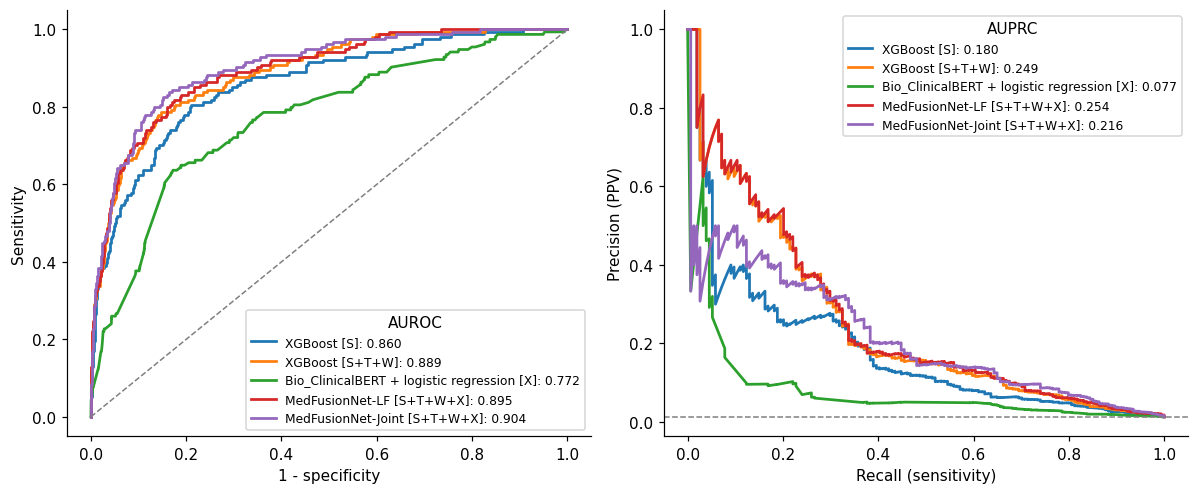

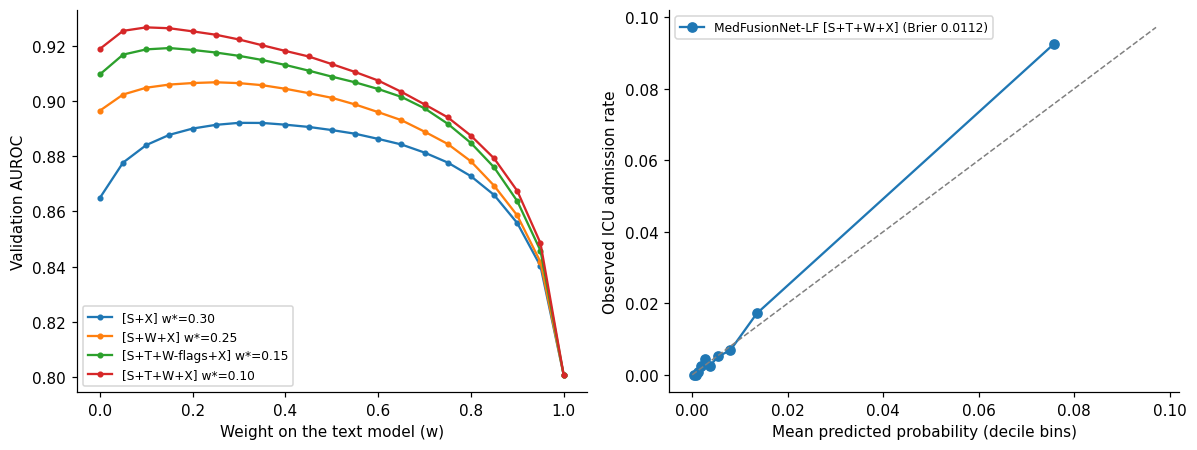

In [11]:
r = CLS["random"]
yt = r["y"]["test"]
show = [k for k in ["S", "S+T+W", "X", "S+T+W|X", "joint"] if k in r["PT"]]
name = lambda k: f"{CLS_LABELS[k][0].split(' (')[0]} [{CLS_LABELS[k][1]}]"

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for k in show:
    fpr, tpr, _ = roc_curve(yt, r["PT"][k])
    ax[0].plot(fpr, tpr, lw=1.8, label=f"{name(k)}: {fast_auc(yt, r['PT'][k]):.3f}")
    pr, rc, _ = precision_recall_curve(yt, r["PT"][k])
    ax[1].plot(rc, pr, lw=1.8, label=f"{name(k)}: {average_precision_score(yt, r['PT'][k]):.3f}")
ax[0].plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax[0].set(xlabel="1 - specificity", ylabel="Sensitivity")
ax[0].legend(title="AUROC", fontsize=8, loc="lower right")
ax[1].axhline(yt.mean(), ls="--", color="grey", lw=1)
ax[1].set(xlabel="Recall (sensitivity)", ylabel="Precision (PPV)")
ax[1].legend(title="AUPRC", fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "fig_icu_roc_pr.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for fk, curve in r["weight_curve"].items():
    ax[0].plot(W_GRID, curve, marker="o", ms=3, lw=1.5, label=f"[{CLS_LABELS[fk][1]}] w*={r['weights'][fk]:.2f}")
ax[0].set(xlabel="Weight on the text model (w)", ylabel="Validation AUROC")
ax[0].legend(fontsize=8)
best = "S+T+W|X"
frac_pos, mean_pred = calibration_curve(yt, r["PT"][best], n_bins=10, strategy="quantile")
ax[1].plot(mean_pred, frac_pos, marker="o", lw=1.5, label=f"{name(best)} (Brier {brier_score_loss(yt, r['PT'][best]):.4f})")
lim = max(mean_pred.max(), frac_pos.max()) * 1.05
ax[1].plot([0, lim], [0, lim], "--", color="grey", lw=1)
ax[1].set(xlabel="Mean predicted probability (decile bins)", ylabel="Observed ICU admission rate")
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig_icu_fusion_weight_calibration.png", bbox_inches="tight"); plt.show()

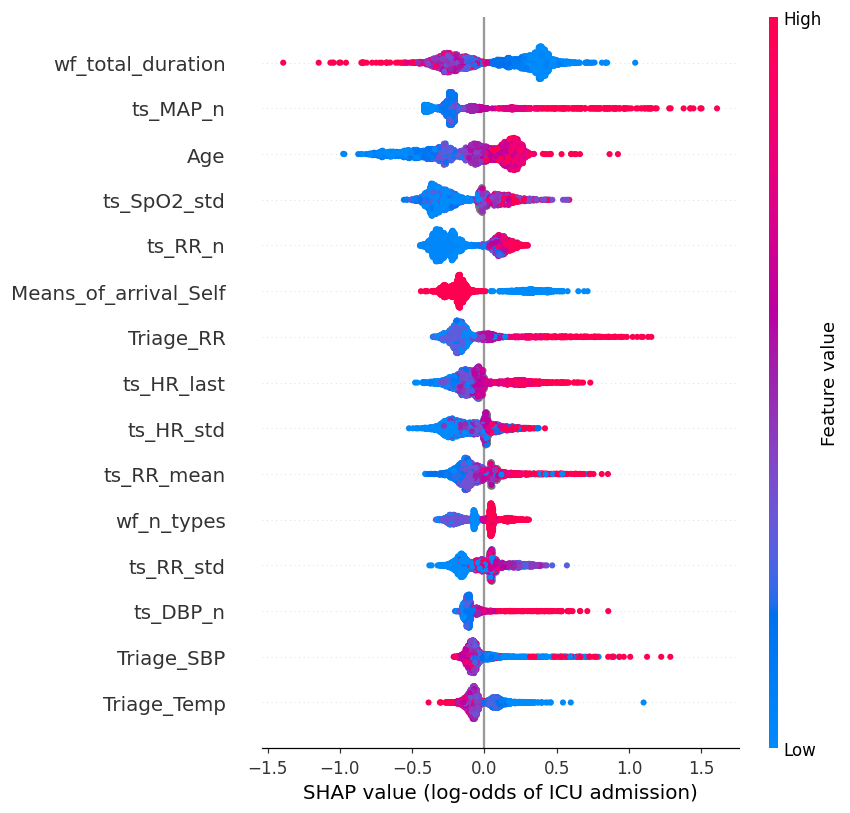

,Feature,Mean |SHAP|
0,wf_total_duration,0.291691
1,ts_MAP_n,0.262308
2,Age,0.238938
3,ts_SpO2_std,0.228328
4,ts_RR_n,0.224481
5,Means_of_arrival_Self,0.218274
6,Triage_RR,0.185881
7,ts_HR_last,0.146084
8,ts_HR_std,0.141750
9,ts_RR_mean,0.125658


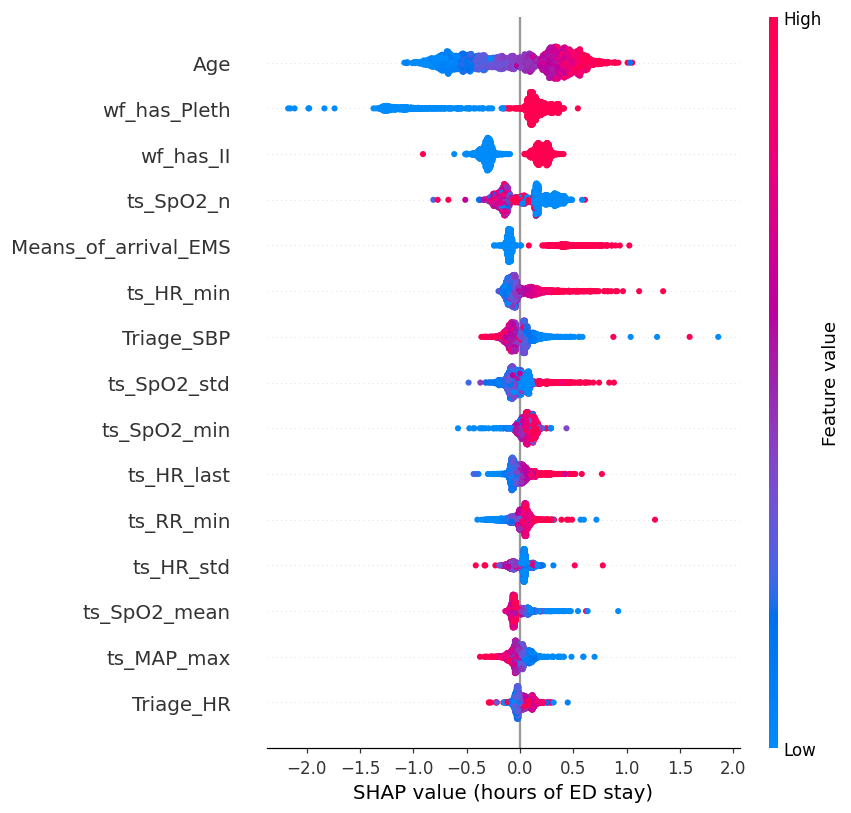

,Feature,Mean |SHAP|
0,Age,0.417380
1,wf_has_Pleth,0.353529
2,wf_has_II,0.254841
3,ts_SpO2_n,0.188097
4,Means_of_arrival_EMS,0.165085
5,ts_HR_min,0.109747
6,Triage_SBP,0.088903
7,ts_SpO2_std,0.085179
8,ts_SpO2_min,0.076742
9,ts_HR_last,0.068213


In [12]:
def shap_figure(pack, path, xlabel, max_rows=3000, top=15):
    """Exact TreeSHAP values from XGBoost (pred_contribs); beeswarm via `shap` if it is installed."""
    model, X, names = pack
    rng = np.random.default_rng(SEED)
    Xs = X[rng.choice(len(X), min(max_rows, len(X)), replace=False)]
    contrib = model.get_booster().predict(xgb.DMatrix(Xs), pred_contribs=True)[:, :-1]
    imp = pd.DataFrame({"Feature": names, "Mean |SHAP|": np.abs(contrib).mean(axis=0)}) \
        .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True)
    try:
        import shap
        plt.figure()
        shap.summary_plot(contrib, Xs, feature_names=names, max_display=top, show=False)
        plt.xlabel(xlabel)
    except Exception as err:
        print("shap beeswarm unavailable, drawing a bar chart instead:", repr(err)[:120])
        plt.figure(figsize=(6.5, 5))
        d = imp.head(top).iloc[::-1]
        plt.barh(d["Feature"], d["Mean |SHAP|"], color="#4c72b0")
        plt.xlabel("Mean |SHAP value|")
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.show()
    return imp


shap_icu = shap_figure(CLS["random"]["shap"], FIG / "fig_shap_icu.png", "SHAP value (log-odds of ICU admission)")
shap_icu.to_csv(OUT / "table_shap_icu.csv", index=False)
display(shap_icu.head(15))
shap_los = shap_figure(LOSR["random"]["shap"], FIG / "fig_shap_los.png", "SHAP value (hours of ED stay)")
shap_los.to_csv(OUT / "table_shap_los.csv", index=False)
display(shap_los.head(15))

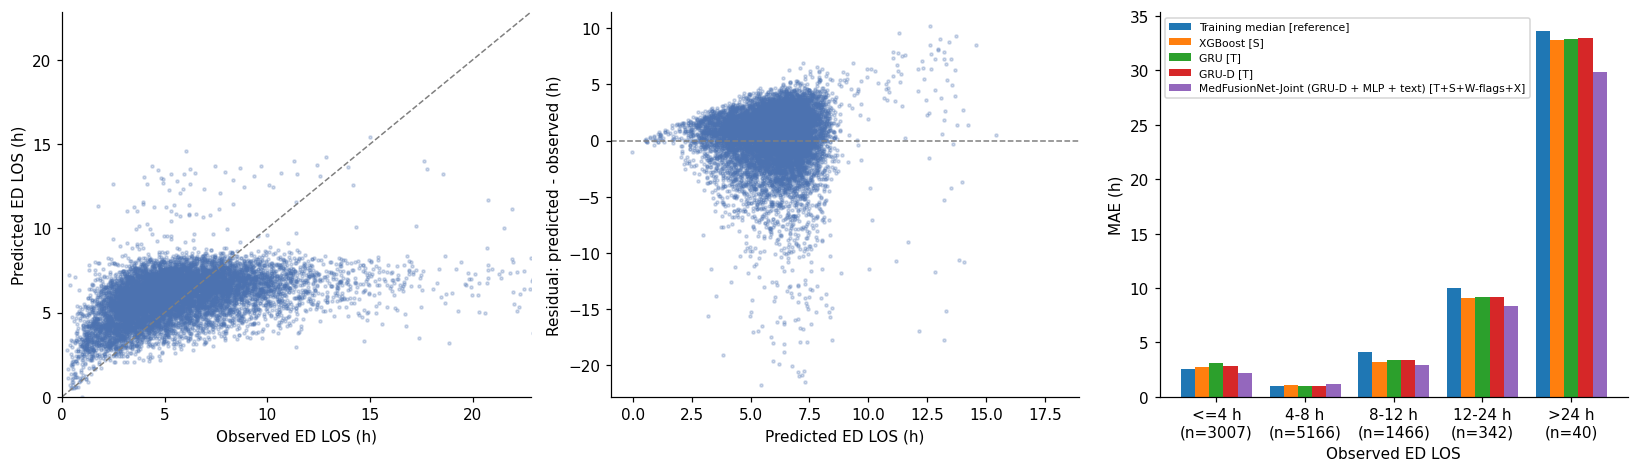

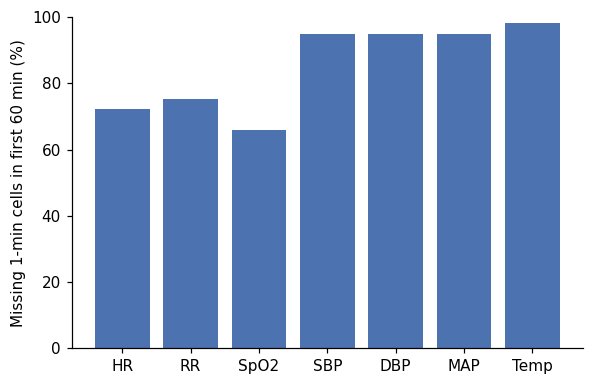

In [13]:
r = LOSR["random"]
yt, k = r["y"], ("joint" if "joint" in r["P"] else "grud")
p = r["P"][k]
lim = float(np.percentile(yt, 99.5))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
ax[0].scatter(yt, p, s=4, alpha=0.25, color="#4c72b0", rasterized=True)
ax[0].plot([0, lim], [0, lim], "--", color="grey", lw=1)
ax[0].set(xlim=(0, lim), ylim=(0, lim), xlabel="Observed ED LOS (h)", ylabel="Predicted ED LOS (h)")
ax[1].scatter(p, p - yt, s=4, alpha=0.25, color="#4c72b0", rasterized=True)
ax[1].axhline(0, ls="--", color="grey", lw=1)
ax[1].set(xlabel="Predicted ED LOS (h)", ylabel="Residual: predicted - observed (h)", ylim=(-lim, lim / 2))
st = r["strata"]
cols = [c for c in st.columns if c.startswith("MAE ")]
x = np.arange(len(st)); w = 0.8 / len(cols)
for i, c in enumerate(cols):
    ax[2].bar(x + i * w, st[c], w, label=c[4:])
ax[2].set_xticks(x + 0.4 - w / 2); ax[2].set_xticklabels([f"{a}\n(n={n})" for a, n in zip(st["LOS range"], st["N"])])
ax[2].set(ylabel="MAE (h)", xlabel="Observed ED LOS"); ax[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig_los_predictions_residuals.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(missing_table["Vital"], missing_table["Missing cells (%)"], color="#4c72b0")
ax.set(ylabel="Missing 1-min cells in first 60 min (%)", ylim=(0, 100))
fig.tight_layout(); fig.savefig(FIG / "fig_temporal_missingness.png", bbox_inches="tight"); plt.show()

## 10. Numbers for the manuscript



In [14]:
def row(table, key):
    t = table[table["key"] == key]
    return None if t.empty else t.iloc[0]


lines = []
for kind in SPLITS:
    c, l = CLS[kind], LOSR[kind]
    lines.append(f"\n=== {kind.upper()} SPLIT ===")
    lines.append(f"ICU admission: test N={len(c['y']['test']):,}, ICU={int(c['y']['test'].sum()):,} "
                 f"({100 * c['y']['test'].mean():.2f}%)")
    for key in ["S", "S+T", "S+W", "S+T+W", "X", "S|X", "S+W|X", "S+T+W|X", "S+T+Wf|X", "early", "joint"]:
        t = row(c["table"], key)
        if t is not None:
            lines.append(f"  {t['Modalities']:<16s} {t['Model']:<46s} AUROC {t['AUROC']:.3f} {t['AUROC 95% CI']}  "
                         f"AUPRC {t['AUPRC']:.3f} {t['AUPRC 95% CI']}  Sens {t['Sensitivity']:.3f} / Spec {t['Specificity']:.3f} "
                         f"/ PPV {t['PPV']:.3f} / F1 {t['F1']:.3f}")
    lines.append(f"  validation-selected text weights: {c['weights']}")
    cand = c["table"][c["table"]["key"].isin(["S+W|X", "S+T+W|X", "early", "joint"])]
    sel = cand.loc[cand["Val AUROC"].idxmax()]
    lines.append(f"  multimodal model with the highest VALIDATION AUROC: {sel['Model']} [{sel['Modalities']}] "
                 f"(val {sel['Val AUROC']:.4f}) - choose the headline model on validation, never on test")
    lines.append(f"ED LOS: test N={l['n']['test']:,} (train {l['n']['train']:,}, val {l['n']['val']:,})")
    for key in LOS_LABELS:
        t = row(l["table"], key)
        if t is not None:
            lines.append(f"  {t['Modalities']:<16s} {t['Model']:<42s} MAE {t['MAE (h)']:.3f} {t['MAE 95% CI']}  "
                         f"RMSE {t['RMSE (h)']:.3f} {t['RMSE 95% CI']}  R2 {t['R2']:.3f}")
summary_text = "\n".join(lines)
print(summary_text)
open(OUT / "manuscript_numbers.txt", "w").write(summary_text)

# LaTeX tables (IEEE two-column friendly)
def to_tex(table, path):
    t = table.copy()
    t.columns = [c.replace("%", r"\%").replace("R2", "$R^2$") for c in t.columns]
    t["Model"] = t["Model"].str.replace("_", r"\_", regex=False)
    open(path, "w").write(t.to_latex(index=False, float_format="%.3f", escape=False))


try:
    for kind in SPLITS:
        to_tex(CLS[kind]["table"][["Model", "Modalities", "AUROC", "AUROC 95% CI", "AUPRC", "AUPRC 95% CI",
                                   "Sensitivity", "Specificity", "F1"]], OUT / f"table_icu_{kind}.tex")
        to_tex(LOSR[kind]["table"][["Model", "Modalities", "MAE (h)", "MAE 95% CI", "RMSE (h)", "RMSE 95% CI", "R2"]],
               OUT / f"table_los_{kind}.tex")
except Exception as err:
    print("LaTeX export skipped:", repr(err)[:150])


=== RANDOM SPLIT ===
ICU admission: test N=11,666, ICU=154 (1.32%)
  S                XGBoost                                        AUROC 0.860 (0.827-0.889)  AUPRC 0.180 (0.128-0.246)  Sens 0.240 / Spec 0.991 / PPV 0.259 / F1 0.249
  S+T              XGBoost                                        AUROC 0.875 (0.845-0.903)  AUPRC 0.234 (0.168-0.313)  Sens 0.253 / Spec 0.994 / PPV 0.355 / F1 0.295
  S+W              XGBoost                                        AUROC 0.879 (0.851-0.906)  AUPRC 0.174 (0.124-0.243)  Sens 0.266 / Spec 0.985 / PPV 0.197 / F1 0.227
  S+T+W            XGBoost                                        AUROC 0.889 (0.863-0.915)  AUPRC 0.249 (0.182-0.328)  Sens 0.325 / Spec 0.989 / PPV 0.281 / F1 0.301
  X                Bio_ClinicalBERT + logistic regression         AUROC 0.772 (0.733-0.810)  AUPRC 0.077 (0.050-0.123)  Sens 0.078 / Spec 0.995 / PPV 0.171 / F1 0.107
  S+X              Late fusion                                    AUROC 0.874 (0.842-0.902)  AUPR